Training set: 120000 samples
Unseen test set: 200 samples
Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 70s 147ms/step - accuracy: 0.7494 - loss: 0.5240 - val_accuracy: 0.9050 - val_loss: 0.2523
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 143ms/step - accuracy: 0.8868 - loss: 0.2899 - val_accuracy: 0.9500 - val_loss: 0.1770
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 143ms/step - accuracy: 0.9024 - loss: 0.2540 - val_accuracy: 0.9450 - val_loss: 0.1706
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 68s 144ms/step - accuracy: 0.9097 - loss: 0.2364 - val_accuracy: 0.9450 - val_loss: 0.1589
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 68s 144ms/step - accuracy: 0.9152 - loss: 0.2219 - val_accuracy: 0.9400 - val_loss: 0.1778
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 68s 144ms/step - accuracy: 0.9221 - loss: 0.2061 - val_accuracy: 0.9400 - val_loss: 0.1637
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 143ms/step - accuracy: 0.9272 - loss: 0.1932 - val_accuracy: 0.9350 - val_loss: 0.1697
1/1 ━━━━━━━━━━━━━━━━━━━━ 

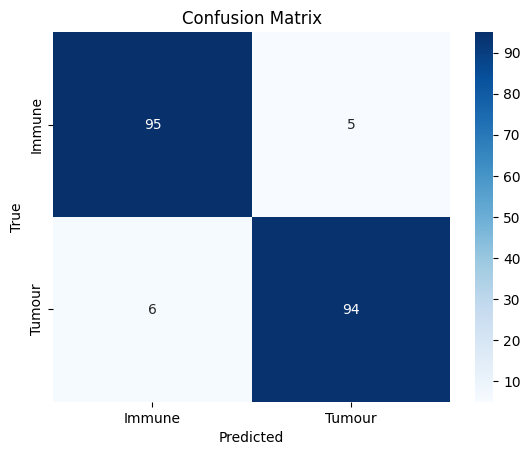

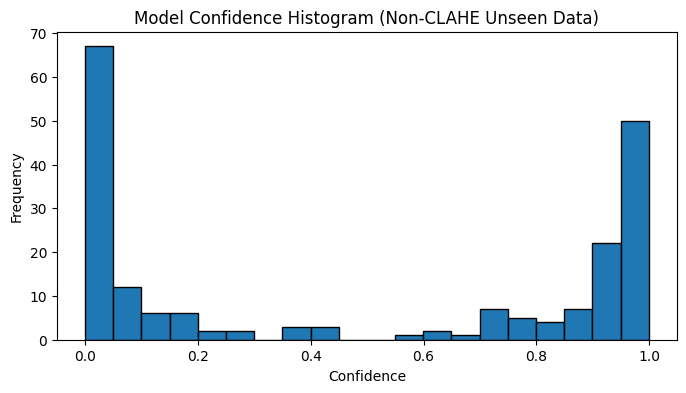

In [6]:
import os
import random
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
from collections import defaultdict
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping


seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

img_width, img_height = 100, 100
batch_size = 256
AUTOTUNE = tf.data.AUTOTUNE


data_dir = os.path.join(os.path.expanduser("~"), "Downloads", "clahe_dataset")
tumour_folders = [os.path.join(data_dir, n) for n in
                  ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]]
immune_folders = [os.path.join(data_dir, n) for n in
                  ["CD4+_T_Cells", "CD8+_T_Cells", "B_Cells", "Stromal"]]


def get_file_label_pairs(folders, main_label):
    out = []
    for folder in folders:
        for f in tf.io.gfile.glob(os.path.join(folder, "*.png")):
            out.append((f, main_label, os.path.basename(folder)))
    return out

def create_balanced_equal_dataset(pairs, target_size=15000):
    by_sub = defaultdict(list)
    for f, m, s in pairs:
        by_sub[s].append((f, m, s))
    balanced = []
    for s, files in by_sub.items():
        n = len(files)
        if n < target_size:
            extras = random.choices(files, k=target_size-n)
            balanced += [(f, m, s, False) for f, m, s in files]
            balanced += [(f, m, s, True ) for f, m, s in extras]
        elif n > target_size:
            sampled = random.sample(files, k=target_size)
            balanced += [(f, m, s, False) for f, m, s in sampled]
        else:
            balanced += [(f, m, s, False) for f, m, s in files]
    random.shuffle(balanced)
    return balanced


tumour_files = get_file_label_pairs(tumour_folders, 1)
immune_files = get_file_label_pairs(immune_folders, 0)
all_file_label_pairs = tumour_files + immune_files


def get_balanced_unseen_set(file_label_pairs, samples_per_class=25):
    class_to_files = defaultdict(list)
    for f, m, s in file_label_pairs:
        class_to_files[s].append((f, m, s))
    unseen = []
    for s, files in class_to_files.items():
        if len(files) < samples_per_class:
            raise ValueError(f"Not enough in class '{s}' to pick {samples_per_class}")
        sel = random.sample(files, samples_per_class)
        unseen += [(f, m, s, False) for f, m, s in sel]
    random.shuffle(unseen)
    return unseen

unseen_pairs     = get_balanced_unseen_set(all_file_label_pairs, 25)
unseen_paths_set = {f for f, *_ in unseen_pairs}
remaining        = [(f,m,s) for f,m,s in all_file_label_pairs if f not in unseen_paths_set]


target_size = 15000
balanced_pairs = create_balanced_equal_dataset(remaining, target_size)
print(f"Training set: {len(balanced_pairs)} samples")
print(f"Unseen test set: {len(unseen_pairs)} samples")


def augment_image(img):
    angle = random.choice([0,90,180,270])
    if angle: img = tf.image.rot90(img, k=angle//90)
    flip = random.choice(['none','horizontal','vertical','both'])
    if flip=='horizontal': img = tf.image.flip_left_right(img)
    if flip=='vertical':   img = tf.image.flip_up_down(img)
    if flip=='both':
        img = tf.image.flip_left_right(img)
        img = tf.image.flip_up_down(img)
    return img

def decode_img(path, augment=False):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, [img_width, img_height]) / 255.0
    return augment_image(img) if augment else img


def build_dataset(pairs, augment_images=False, shuffle_data=False):
    paths, labels, aug = [], [], []
    for f, m, s, overs in pairs:
        paths.append(f)
        labels.append(m)
        aug.append(overs if augment_images else False)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, aug))
    ds = ds.map(lambda p,l,a: (decode_img(p, augment=a), l),
                num_parallel_calls=AUTOTUNE)
    if shuffle_data: ds = ds.shuffle(1000)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = build_dataset(balanced_pairs, augment_images=True,  shuffle_data=True)
test_ds  = build_dataset(unseen_pairs,  augment_images=False, shuffle_data=False)


model = tf.keras.Sequential([
    tf.keras.layers.Input((img_width, img_height, 3)),
    tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Conv2D(64,(3,3),activation='relu'),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss',
                           patience=3,
                           restore_best_weights=True)

history = model.fit(train_ds,
                    validation_data=test_ds,
                    epochs=20,
                    callbacks=[early_stop])



y_pred_probs   = model.predict(test_ds)
y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()


y_true = np.concatenate([lbl.numpy() for _, lbl in test_ds], axis=0)


print(classification_report(y_true, y_pred_classes,
                            target_names=["Immune","Tumour"]))
cm = confusion_matrix(y_true, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Immune","Tumour"],
            yticklabels=["Immune","Tumour"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

confidences = y_pred_probs.flatten()

plt.figure(figsize=(8,4))
plt.hist(confidences, bins=20, edgecolor='black')
plt.title("Model Confidence Histogram (Non-CLAHE Unseen Data)")
plt.xlabel("Confidence"); plt.ylabel("Frequency")
plt.show()

model.save("binary_CLAHE_model.keras")


import pandas as pd
hist_df = pd.DataFrame(history.history)
hist_df.to_excel("binary_CLAHE_history.xlsx", index=False)


In [2]:
import matplotlib.gridspec as gridspec


fig = plt.figure(figsize=(10, 8))
gs = gridspec.GridSpec(2, 1, height_ratios=[2, 2], hspace=0.3)


ax0 = plt.subplot(gs[0])
ax0.plot(history.history['loss'], 'o-', label='Train Loss', color='red')
ax0.plot(history.history['val_loss'], 'o-', label='Val Loss', color='blue')
ax0.set_ylabel('Loss')
ax0.set_title('Training and Validation Loss')
ax0.legend()
ax0.grid(True)


ax1 = plt.subplot(gs[1], sharex=ax0)
ax1.plot(history.history['accuracy'], 'o-', label='Train Accuracy', color='red')
ax1.plot(history.history['val_accuracy'], 'o-', label='Val Accuracy', color='blue')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_title('Training and Validation Accuracy')
ax1.legend()
ax1.grid(True)

plt.show()

NameError: name 'plt' is not defined

In [5]:
model.save("binary_NONCLAHE_model.keras")

import pandas as pd
hist_df = pd.DataFrame(history.history)
hist_df.to_excel("binary_NONCLAHE_history.xlsx", index=False)